# Document Similarity Analysis Using Shingling and Locality Sensitive Hashing (LSH)

**Mapped CO:** CO3  
**Aim:** Identify and evaluate document similarity using Shingling, Jaccard Similarity, MinHash, and Locality Sensitive Hashing (LSH).

## Objectives
- Represent each document as a set of overlapping word shingles.
- Compute exact Jaccard similarity between document pairs.
- Build compact MinHash signatures to estimate Jaccard similarity.
- Use an LSH index to retrieve likely-similar documents without checking every pair.
- Observe the effect of shingle size and similarity thresholds.

## Theory
A **shingle** is a consecutive sequence of *k* words (or characters). With word shingles and `k = 3`, the text `machine learning finds patterns` produces `machine learning finds` and `learning finds patterns`.

For shingle sets \(A\) and \(B\), **Jaccard similarity** is

\[
J(A,B)=\frac{|A\cap B|}{|A\cup B|}
\]

It ranges from 0 (no shared shingles) to 1 (identical shingle sets).

**MinHash** compresses a set into a signature. For a suitable MinHash function \(h\),

\[
P[h(A)=h(B)] = J(A,B)
\]

With `m` independent signature positions, the fraction of matching positions estimates Jaccard similarity.

**Locality Sensitive Hashing (LSH)** divides signatures into bands and retrieves documents that share at least one band. It is approximate: it can produce false positives and false negatives. Candidates should be checked with exact Jaccard similarity when correctness matters.

For `b` bands with `r` rows per band, the idealized probability of becoming a candidate at true similarity `s` is

\[
P(\text{candidate})=1-(1-s^r)^b
\]

## Workflow
1. Load sample documents.
2. Normalize text and create word shingles.
3. Compute exact Jaccard similarities.
4. Create MinHash signatures.
5. Build and query an LSH index.
6. Compare LSH candidates against exact similarity and inspect the results.

> **Note:** The notebook uses the `datasketch` package when it is installed. If it is unavailable, an educational fallback implementation of MinHash and banded LSH is used so the experiment can still run offline. Install `datasketch` for the package-based implementation: `%pip install datasketch`.

## 1. Import libraries and select implementation

In [1]:
import re
import hashlib
from itertools import combinations
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from datasketch import MinHash, MinHashLSH
    DATASKETCH_AVAILABLE = True
    print("datasketch is available: using MinHash and MinHashLSH from datasketch.")
except ImportError:
    DATASKETCH_AVAILABLE = False
    print("datasketch is not installed: using the notebook's educational fallback implementation.")
    print("For the library implementation, run: %pip install datasketch")

NUM_PERM = 128
LSH_THRESHOLD = 0.30
RANDOM_SEED = 42

datasketch is not installed: using the notebook's educational fallback implementation.
For the library implementation, run: %pip install datasketch


## 2. Create or load the document collection

In [2]:
documents = {
    "D1": "The quick brown fox jumps over the lazy dog. The quick brown fox enjoys running in the forest.",
    "D2": "The quick brown fox jumps over the lazy dog. The quick brown fox enjoys running through the forest.",
    "D3": "Machine learning algorithms learn patterns from training data and make predictions.",
    "D4": "Machine learning algorithms learn patterns from data and make predictions using neural networks.",
    "D5": "Search engines use document similarity to find duplicate pages and detect plagiarism. MinHash and LSH help find similar documents efficiently.",
    "D6": "Search engines use document similarity to find duplicate pages and detect plagiarism. LSH helps find similar documents quickly."
}

df = pd.DataFrame(
    [{"Document ID": doc_id, "Text": text} for doc_id, text in documents.items()]
)
display(df)
print(f"Loaded {len(df)} documents successfully.")

,Document ID,Text
0,D1,The quick brown fox jumps over the lazy dog. T...
1,D2,The quick brown fox jumps over the lazy dog. T...
2,D3,Machine learning algorithms learn patterns fro...
3,D4,Machine learning algorithms learn patterns fro...
4,D5,Search engines use document similarity to find...
5,D6,Search engines use document similarity to find...


Loaded 6 documents successfully.


## 3. Normalize text and generate word shingles

Normalization in this experiment is deliberately simple: lowercase the text, replace punctuation/non-alphanumeric characters with spaces, and split into words. A shingle is a sequence of `k` consecutive words. We store shingles in a **set**, so repeated occurrences of the same shingle count only once.

In [3]:
def tokenize(text: str) -> list[str]:
    """Lowercase text and keep word-like tokens."""
    return re.findall(r"\b\w+\b", text.lower())


def make_shingles(text: str, k: int = 3) -> set[str]:
    """Create a set of overlapping k-word shingles from text."""
    if k < 1:
        raise ValueError("k must be at least 1")
    tokens = tokenize(text)
    return {" ".join(tokens[i:i + k]) for i in range(len(tokens) - k + 1)}

K = 3
shingle_sets = {doc_id: make_shingles(text, K) for doc_id, text in documents.items()}

shingle_summary = pd.DataFrame([
    {
        "Document ID": doc_id,
        "Word count": len(tokenize(documents[doc_id])),
        "Unique shingles": len(shingles),
        "Example shingles": "; ".join(sorted(shingles)[:5])
    }
    for doc_id, shingles in shingle_sets.items()
])
display(shingle_summary)

# Preview all shingles from one document.
print(f"\nShingles for D1 (k={K}):")
print(sorted(shingle_sets["D1"]))

,Document ID,Word count,Unique shingles,Example shingles
0,D1,18,14,brown fox enjoys; brown fox jumps; dog the qui...
1,D2,18,14,brown fox enjoys; brown fox jumps; dog the qui...
2,D3,11,9,algorithms learn patterns; and make prediction...
3,D4,13,11,algorithms learn patterns; and make prediction...
4,D5,20,18,and detect plagiarism; and lsh help; detect pl...
5,D6,18,16,and detect plagiarism; detect plagiarism lsh; ...



Shingles for D1 (k=3):
['brown fox enjoys', 'brown fox jumps', 'dog the quick', 'enjoys running in', 'fox enjoys running', 'fox jumps over', 'in the forest', 'jumps over the', 'lazy dog the', 'over the lazy', 'quick brown fox', 'running in the', 'the lazy dog', 'the quick brown']


## 4. Compute exact Jaccard Similarity

In [4]:
def jaccard_similarity(set_a: set[str], set_b: set[str]) -> float:
    """Exact Jaccard similarity for two sets."""
    union = set_a | set_b
    if not union:
        return 1.0  # two empty sets are treated as identical
    return len(set_a & set_b) / len(union)


doc_ids = list(documents)
jaccard_matrix = pd.DataFrame(index=doc_ids, columns=doc_ids, dtype=float)
for id_a in doc_ids:
    for id_b in doc_ids:
        jaccard_matrix.loc[id_a, id_b] = jaccard_similarity(
            shingle_sets[id_a], shingle_sets[id_b]
        )

display(jaccard_matrix.round(3).style.format("{:.3f}"))

# Display each distinct pair, sorted from most to least similar.
pair_rows = []
for id_a, id_b in combinations(doc_ids, 2):
    pair_rows.append({
        "Document A": id_a,
        "Document B": id_b,
        "Intersection size": len(shingle_sets[id_a] & shingle_sets[id_b]),
        "Union size": len(shingle_sets[id_a] | shingle_sets[id_b]),
        "Jaccard Similarity": jaccard_similarity(shingle_sets[id_a], shingle_sets[id_b])
    })
pair_results = pd.DataFrame(pair_rows).sort_values("Jaccard Similarity", ascending=False)
display(pair_results.round(3))

,D1,D2,D3,D4,D5,D6
D1,1.000,0.647,0.000,0.000,0.000,0.000
D2,0.647,1.000,0.000,0.000,0.000,0.000
D3,0.000,0.000,1.000,0.429,0.000,0.000
D4,0.000,0.000,0.429,1.000,0.000,0.000
D5,0.000,0.000,0.000,0.000,1.000,0.478
D6,0.000,0.000,0.000,0.000,0.478,1.000


,Document A,Document B,Intersection size,Union size,Jaccard Similarity
0,D1,D2,11,17,0.647
14,D5,D6,11,23,0.478
9,D3,D4,6,14,0.429
3,D1,D5,0,32,0.000
4,D1,D6,0,30,0.000
1,D1,D3,0,23,0.000
2,D1,D4,0,25,0.000
6,D2,D4,0,25,0.000
5,D2,D3,0,23,0.000
8,D2,D6,0,30,0.000


### Visualize the exact similarity matrix

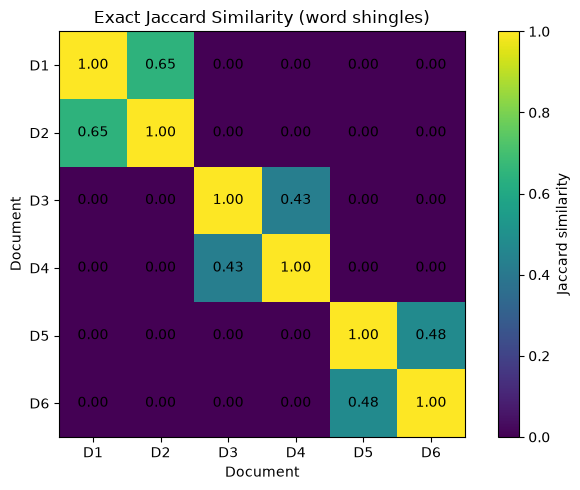

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(jaccard_matrix.to_numpy(dtype=float), vmin=0, vmax=1)
ax.set_xticks(range(len(doc_ids)), doc_ids)
ax.set_yticks(range(len(doc_ids)), doc_ids)
ax.set_title("Exact Jaccard Similarity (word shingles)")
ax.set_xlabel("Document")
ax.set_ylabel("Document")
for i in range(len(doc_ids)):
    for j in range(len(doc_ids)):
        ax.text(j, i, f"{jaccard_matrix.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Jaccard similarity")
plt.tight_layout()
plt.show()

## 5. Generate MinHash signatures

Each document's shingle set is mapped to a signature with 128 positions. The signature is much smaller than storing every set comparison, and the fraction of matching signature positions estimates Jaccard similarity.

In [6]:
# Parameters for the deterministic fallback implementation. They are only used
# when datasketch is not installed.
_PRIME = 2**61 - 1
_rng = np.random.default_rng(RANDOM_SEED)
_A = _rng.integers(1, _PRIME, size=NUM_PERM, dtype=np.int64)
_B = _rng.integers(0, _PRIME, size=NUM_PERM, dtype=np.int64)


def fallback_minhash_signature(shingles: set[str]) -> np.ndarray:
    """Small, deterministic educational MinHash implementation."""
    if not shingles:
        return np.full(NUM_PERM, _PRIME, dtype=np.int64)
    token_hashes = [
        int.from_bytes(hashlib.sha1(shingle.encode("utf-8")).digest()[:8], "big") % _PRIME
        for shingle in shingles
    ]
    signature = []
    for a, b in zip(_A, _B):
        signature.append(min((int(a) * x + int(b)) % _PRIME for x in token_hashes))
    return np.array(signature, dtype=np.int64)


def create_sketch(shingles: set[str]):
    """Use datasketch MinHash if available, otherwise use the fallback."""
    if DATASKETCH_AVAILABLE:
        sketch = MinHash(num_perm=NUM_PERM, seed=RANDOM_SEED)
        for shingle in shingles:
            sketch.update(shingle.encode("utf-8"))
        return sketch
    return fallback_minhash_signature(shingles)


sketches = {doc_id: create_sketch(shingles) for doc_id, shingles in shingle_sets.items()}
print(f"Created {len(sketches)} MinHash signatures with {NUM_PERM} permutations each.")


def estimated_similarity(sketch_a, sketch_b) -> float:
    if DATASKETCH_AVAILABLE:
        return float(sketch_a.jaccard(sketch_b))
    return float(np.mean(sketch_a == sketch_b))

estimate_rows = []
for id_a, id_b in combinations(doc_ids, 2):
    exact = jaccard_similarity(shingle_sets[id_a], shingle_sets[id_b])
    estimate = estimated_similarity(sketches[id_a], sketches[id_b])
    estimate_rows.append({
        "Document A": id_a,
        "Document B": id_b,
        "Exact Jaccard": exact,
        "MinHash estimate": estimate,
        "Absolute error": abs(exact - estimate)
    })
minhash_comparison = pd.DataFrame(estimate_rows).sort_values("Exact Jaccard", ascending=False)
display(minhash_comparison.round(3))

Created 6 MinHash signatures with 128 permutations each.


,Document A,Document B,Exact Jaccard,MinHash estimate,Absolute error
0,D1,D2,0.647,0.695,0.048
14,D5,D6,0.478,0.516,0.037
9,D3,D4,0.429,0.477,0.048
3,D1,D5,0.000,0.000,0.000
4,D1,D6,0.000,0.000,0.000
1,D1,D3,0.000,0.000,0.000
2,D1,D4,0.000,0.000,0.000
6,D2,D4,0.000,0.000,0.000
5,D2,D3,0.000,0.000,0.000
8,D2,D6,0.000,0.000,0.000


## 6. Build the LSH index and query similar documents

The chosen threshold is `0.30`. With `datasketch`, the library chooses banding parameters for that threshold. The fallback uses 64 bands with 2 signature positions per band. That fallback is for learning and offline execution; it approximates the idea of LSH but does not reproduce the library's threshold optimizer exactly.

In [7]:
if DATASKETCH_AVAILABLE:
    lsh_index = MinHashLSH(threshold=LSH_THRESHOLD, num_perm=NUM_PERM)
    for doc_id, sketch in sketches.items():
        lsh_index.insert(doc_id, sketch)

    def query_lsh(sketch):
        return sorted(lsh_index.query(sketch))

    print(f"Built datasketch LSH index (threshold={LSH_THRESHOLD:.2f}, num_perm={NUM_PERM}).")
else:
    FALLBACK_BANDS = 64
    FALLBACK_ROWS = NUM_PERM // FALLBACK_BANDS
    fallback_buckets = defaultdict(set)

    for doc_id, signature in sketches.items():
        for band in range(FALLBACK_BANDS):
            start = band * FALLBACK_ROWS
            band_key = (band, tuple(int(x) for x in signature[start:start + FALLBACK_ROWS]))
            fallback_buckets[band_key].add(doc_id)

    def query_lsh(signature):
        candidates = set()
        for band in range(FALLBACK_BANDS):
            start = band * FALLBACK_ROWS
            band_key = (band, tuple(int(x) for x in signature[start:start + FALLBACK_ROWS]))
            candidates.update(fallback_buckets.get(band_key, set()))
        return sorted(candidates)

    print(f"Built fallback banded-LSH index ({FALLBACK_BANDS} bands × {FALLBACK_ROWS} rows).")

lsh_rows = []
for doc_id in doc_ids:
    candidates = [candidate for candidate in query_lsh(sketches[doc_id]) if candidate != doc_id]
    if not candidates:
        lsh_rows.append({
            "Query document": doc_id,
            "LSH candidate": "(no other candidates)",
            "Exact Jaccard": np.nan,
            "At/above chosen threshold?": "—"
        })
    else:
        for candidate in candidates:
            exact = jaccard_similarity(shingle_sets[doc_id], shingle_sets[candidate])
            lsh_rows.append({
                "Query document": doc_id,
                "LSH candidate": candidate,
                "Exact Jaccard": exact,
                "At/above chosen threshold?": "Yes" if exact >= LSH_THRESHOLD else "No"
            })

lsh_results = pd.DataFrame(lsh_rows)
display(lsh_results.round(3))

Built fallback banded-LSH index (64 bands × 2 rows).


,Query document,LSH candidate,Exact Jaccard,At/above chosen threshold?
0,D1,D2,0.647,Yes
1,D2,D1,0.647,Yes
2,D3,D4,0.429,Yes
3,D4,D3,0.429,Yes
4,D5,D6,0.478,Yes
5,D6,D5,0.478,Yes


### Count candidate pairs versus all possible pairs

In [8]:
candidate_pairs = set()
for doc_id in doc_ids:
    for candidate in query_lsh(sketches[doc_id]):
        if candidate != doc_id:
            candidate_pairs.add(tuple(sorted((doc_id, candidate))))

all_possible_pairs = len(doc_ids) * (len(doc_ids) - 1) // 2
print(f"All possible unique document pairs: {all_possible_pairs}")
print(f"Unique pairs returned as LSH candidates: {len(candidate_pairs)}")
print("Important: LSH candidate count is not the same as the number of verified-similar pairs.")
print("For a tiny dataset, the overhead of building the index can outweigh any speed benefit;")
print("the advantage becomes clearer for large document collections.")

All possible unique document pairs: 15
Unique pairs returned as LSH candidates: 3
Important: LSH candidate count is not the same as the number of verified-similar pairs.
For a tiny dataset, the overhead of building the index can outweigh any speed benefit;
the advantage becomes clearer for large document collections.


## 7. Assignment 1 — Compute Jaccard similarity for two documents

In [9]:
# Change these IDs to compare any two documents.
DOC_A, DOC_B = "D1", "D2"
print(f"Jaccard({DOC_A}, {DOC_B}) = "
      f"{jaccard_similarity(shingle_sets[DOC_A], shingle_sets[DOC_B]):.4f}")

Jaccard(D1, D2) = 0.6471


## 8. Assignment 2 — Change the shingle size

In [10]:
# Compare selected document pairs using several word-shingle sizes.
selected_pairs = [("D1", "D2"), ("D3", "D4"), ("D5", "D6")]
rows = []
for k in [2, 3, 4, 5]:
    these_shingles = {doc_id: make_shingles(text, k) for doc_id, text in documents.items()}
    for id_a, id_b in selected_pairs:
        rows.append({
            "Shingle size k": k,
            "Pair": f"{id_a}–{id_b}",
            "Jaccard Similarity": jaccard_similarity(these_shingles[id_a], these_shingles[id_b])
        })
shingle_size_effect = pd.DataFrame(rows)
display(shingle_size_effect.pivot(index="Shingle size k", columns="Pair", values="Jaccard Similarity").round(3))
print("Interpretation: changing k changes which sequences count as matches; similarity may rise or fall.")

Pair,D1–D2,D3–D4,D5–D6
Shingle size k,,,
2,0.750,0.571,0.565
3,0.647,0.429,0.478
4,0.647,0.286,0.391
5,0.647,0.143,0.364


Interpretation: changing k changes which sequences count as matches; similarity may rise or fall.


## 9. Assignment 3 — Add a new document and query the LSH index

The index below was built from D1–D6. We can create a sketch for a new document and query the existing index without rebuilding it. If desired, insert the new document after querying it.

In [11]:
new_doc_id = "D7"
new_text = "Search engines use document similarity to find duplicate pages and detect plagiarism. MinHash helps search engines find similar documents efficiently."
new_shingles = make_shingles(new_text, K)
new_sketch = create_sketch(new_shingles)

new_candidates = [doc_id for doc_id in query_lsh(new_sketch) if doc_id != new_doc_id]
print("New document:", new_text)
print("LSH candidates:", new_candidates if new_candidates else "No candidates returned by LSH")

# Verify candidate results using exact Jaccard similarity.
new_candidate_checks = pd.DataFrame([
    {
        "New document": new_doc_id,
        "Candidate": candidate,
        "Exact Jaccard": jaccard_similarity(new_shingles, shingle_sets[candidate]),
        "At/above threshold?": "Yes" if jaccard_similarity(new_shingles, shingle_sets[candidate]) >= LSH_THRESHOLD else "No"
    }
    for candidate in new_candidates
])
if new_candidate_checks.empty:
    print("No candidate was returned; LSH is approximate, so this does not prove that no similar document exists.")
else:
    display(new_candidate_checks.sort_values("Exact Jaccard", ascending=False).round(3))

# Exact all-document comparison, as a ground-truth check for this small example.
new_exact_checks = pd.DataFrame([
    {"Document": doc_id, "Exact Jaccard": jaccard_similarity(new_shingles, shingles)}
    for doc_id, shingles in shingle_sets.items()
]).sort_values("Exact Jaccard", ascending=False)
display(new_exact_checks.round(3))

New document: Search engines use document similarity to find duplicate pages and detect plagiarism. MinHash helps search engines find similar documents efficiently.
LSH candidates: ['D5', 'D6']


,New document,Candidate,Exact Jaccard,At/above threshold?
0,D7,D5,0.565,Yes
1,D7,D6,0.478,Yes


,Document,Exact Jaccard
4,D5,0.565
5,D6,0.478
1,D2,0.000
0,D1,0.000
3,D4,0.000
2,D3,0.000


## 10. Assignment 4 — Compare similarity thresholds

In [12]:
thresholds = [0.20, 0.30, 0.50, 0.70]
threshold_rows = []

if DATASKETCH_AVAILABLE:
    for threshold in thresholds:
        threshold_lsh = MinHashLSH(threshold=threshold, num_perm=NUM_PERM)
        for doc_id, sketch in sketches.items():
            threshold_lsh.insert(doc_id, sketch)

        seen_pairs = set()
        for doc_id, sketch in sketches.items():
            for candidate in threshold_lsh.query(sketch):
                if candidate != doc_id:
                    seen_pairs.add(tuple(sorted((doc_id, candidate))))

        verified_pairs = sum(
            1 for id_a, id_b in seen_pairs
            if jaccard_similarity(shingle_sets[id_a], shingle_sets[id_b]) >= threshold
        )
        threshold_rows.append({
            "LSH threshold": threshold,
            "Candidate pairs": len(seen_pairs),
            "Candidates verified at/above threshold": verified_pairs
        })
    display(pd.DataFrame(threshold_rows))
else:
    # Compare exact-similarity cutoffs offline. This is the ground-truth threshold
    # comparison; the fallback LSH index above uses fixed banding instead.
    for threshold in thresholds:
        exact_pairs = [
            (id_a, id_b, jaccard_similarity(shingle_sets[id_a], shingle_sets[id_b]))
            for id_a, id_b in combinations(doc_ids, 2)
            if jaccard_similarity(shingle_sets[id_a], shingle_sets[id_b]) >= threshold
        ]
        threshold_rows.append({
            "Exact Jaccard threshold": threshold,
            "Pairs meeting threshold": len(exact_pairs),
            "Matching pairs": ", ".join(f"{a}-{b}" for a, b, _ in exact_pairs) or "None"
        })
    display(pd.DataFrame(threshold_rows))
    print("Install datasketch to rebuild the LSH index separately at each threshold.")

,Exact Jaccard threshold,Pairs meeting threshold,Matching pairs
0,0.2,3,"D1-D2, D3-D4, D5-D6"
1,0.3,3,"D1-D2, D3-D4, D5-D6"
2,0.5,1,D1-D2
3,0.7,0,None


Install datasketch to rebuild the LSH index separately at each threshold.


## 11. Assignment 5 — Advantages of LSH over direct comparison

- **Direct comparison:** for `n` documents, comparing every distinct pair requires \(n(n-1)/2\) pairwise similarity calculations. This grows quadratically.
- **LSH indexing:** signatures are bucketed so that likely-similar documents can be retrieved as candidates; it avoids checking every pair in many large-scale workloads.
- **Trade-off:** LSH is approximate. A candidate can be dissimilar (false positive), and a genuinely similar document can be missed (false negative). Verify candidates with exact Jaccard similarity when needed.
- **Shingle-size trade-off:** small `k` is more tolerant of small text edits but can make unrelated documents look similar; large `k` is more specific but may miss documents after edits.
- **Threshold trade-off:** a lower threshold generally aims for higher recall and more candidates; a higher threshold generally aims for stricter similarity and fewer candidates. Actual behavior depends on the LSH banding configuration.

## 12. Test cases and observations

In [13]:
# Compact checklist of the experiment's key steps.
test_cases = pd.DataFrame([
    {"Test case": "Load documents", "Status": "PASS" if len(documents) > 0 else "FAIL"},
    {"Test case": "Generate shingles", "Status": "PASS" if all(isinstance(s, set) for s in shingle_sets.values()) else "FAIL"},
    {"Test case": "Calculate Jaccard similarity", "Status": "PASS" if jaccard_matrix.shape == (len(documents), len(documents)) else "FAIL"},
    {"Test case": "Create MinHash sketches", "Status": "PASS" if len(sketches) == len(documents) else "FAIL"},
    {"Test case": "Build and query LSH", "Status": "PASS" if callable(query_lsh) else "FAIL"},
])
display(test_cases)

print("\nObservation:")
print("1. Each document was represented by a set of word shingles.")
print("2. Jaccard similarity gave an exact overlap score for each document pair.")
print("3. MinHash signatures provided compact approximate similarity estimates.")
print("4. LSH returned candidate documents; exact Jaccard scores can verify those candidates.")

,Test case,Status
0,Load documents,PASS
1,Generate shingles,PASS
2,Calculate Jaccard similarity,PASS
3,Create MinHash sketches,PASS
4,Build and query LSH,PASS



Observation:
1. Each document was represented by a set of word shingles.
2. Jaccard similarity gave an exact overlap score for each document pair.
3. MinHash signatures provided compact approximate similarity estimates.
4. LSH returned candidate documents; exact Jaccard scores can verify those candidates.


## Result and conclusion

Document similarity analysis was implemented using word shingling, exact Jaccard similarity, MinHash signatures, and an LSH index. The Jaccard matrix shows the exact similarities for this sample corpus, while LSH retrieves a smaller set of candidate pairs for verification. LSH is most valuable on large collections where exhaustive pairwise comparison is expensive; it is approximate, so candidates should be verified when false matches or missed matches matter.

### Viva questions to prepare
1. What is a shingle, and why do we use a set of shingles?
2. Why is Jaccard similarity suitable for shingle sets?
3. What does MinHash estimate, and what does `num_perm` control?
4. How does LSH reduce the number of comparisons?
5. What are false positives and false negatives in LSH?
6. How might the choice of shingle size affect plagiarism detection?